# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
print("plans")
print(plans.head())

plans
  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [4]:
print("\nUsers")
print(users.head())


Users
   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [5]:
print("\nUsage")
print(usage.head())


Usage
   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:

print("\nPlans")
plans.info()



Plans
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
print("\nusers")
users.info()


users
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
print("\nusage")
usage.info()



usage
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("nulos en users")
print(users.isna(). sum())

nulos en users
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


In [11]:
print("nulos en usage")
print(usage.isna().sum())


nulos en usage
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


In [12]:
print("\nProporción de nulos en Users")
print(users.isna().mean())

print("\nProporción de nulos en Usage")
print(usage.isna().mean())


Proporción de nulos en Users
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64

Proporción de nulos en Usage
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---
**Valores nulos**

- **city**: 469 nulos (11.7%). Acción: dejar como nulo (sin imputar). Está en el rango 5–30% y es categórica; imputar una ciudad inventaría información.
- **churn_date**: 3,534 nulos (88.4%). Acción: conservar y dejar los nulos. Un nulo significa que el cliente sigue activo
- **date**: 50 nulos (0.1%). Acción: dejar como nulo. Son muy pocos y una fecha no se puede imputar de forma confiable
- **duration**: 22,076 nulos (55.2%). Acción: dejar como nulo. No aplica a los mensajes
- **length**: 17,896 nulos (44.7%). Acción: dejar como nulo. No aplica a las llamadas

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
print ("users")
print (users.describe())

users
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` va de 10,000 a 13,999, con 4,000 registros y sin huecos, la media y la mediana coinciden, lo que indica que son indicadores consecutivos, no es una variable de consumo, asi qye no tiene sentido interpretarla estadísticamente y no hay valores raros.
- La columna `age` tieneun sentinel, el mínimo es de -999 un valor imposible, reemplazaría -999 por NaN y revisar si hay otros valors invalidos como 0 o edades menores a 18

In [14]:
print ("\nusage")
print (usage.describe())


usage
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` son identificadores, no variables de consumo. id va de 1 a 40,0000 sin huecos, y user id va de 10,000 a 13,999, el mismo rango que en users, así que se pueden relacionar, no muestran valores raros.
-  Las columnas `duration`t `length` no tienen sentinels evidentes, yo revisaría:
-  duration: va de 0 a 120 cin mediana de 3.5, y media de 5.2, el 75% está en 6.99, un maximo de 120 es muy alto, son posibles outliers
-  length: va de 0 a 1,490 con mediana de 50, y media de 52.1. el 75% es 64, un maximo de 1,490 es desproporcionado y parece ser un outlier
-  ambas columnas tienen ausentes (17924.000000 y 22104.000000 registros con valor)

In [15]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print (col)
    print (users[col].value_counts(dropna=False))
    print()


city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` tiene 7 ciudades válidas, más dos probelmas, los 469 valores nulos y 96 registros con "?", que es un sentinel de texto.
- Acción:reemplazar "?" por "NaN" para unificarlo con los nulos y dejarlos sin imputar una ciudad.
- La columna `plan` solo tiene dos valores, "Básico" y "Premium" con 2,595 y 1,405 usuarios, sin nulos ni variante de escritura, no requiere limpieza

In [16]:
# explorar columna categórica de usage
print (usage['type'].value_counts(dropna=False))

text    22092
call    17908
Name: type, dtype: int64


- La columna `type` iene solo 2 valores, text (22,092) y call (17,908), sin nulos ni variantes de escritura, no requiere limpieza 



---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
- ¿En qué columnas encontré valores inválidos o sentinels?

-age (users): el mínimo es -999, un valor imposible para una edad. Es un sentinel y también explica la desviación estándar tan alta (123.2).
-city (users): hay 96 registros con "?" (2.4%), además de los 469 nulos que ya teníamos.
-duration y length (usage): no hay sentinels claros, pero hay valores en 0 y máximos muy altos (120 y 1,490) que parecen posibles outliers o errores de registro.
-plan (users) y type (usage): sin valores inválidos.

¿Qué acción tomaría?

-age:
-reemplazar -999 por NaN y revisar si hay otros valores raros (0 o menores de 18). Es un dato imposible y distorsiona la media y la desviación estándar.
-city: reemplazar "?" por NaN, para unificarlo con los nulos, y no imputar.Inventar una ciudad distorsionaría la comparación entre segmentos.
-duration y length: no eliminar todavía, analizarlos con IQR y boxplots, los extremos pueden ser comportamientos reales, hay que revisarlos antes de decidir.
 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') 

In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [19]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())
print(usage['date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64
2024.0    39950
Name: date, dtype: int64


En `reg_date` (users) los años 2022, 2023, y 2024 tienen una vamtidad similar de registros ( 1,314 y 1,330), pero aparecen 40 registros con el año 2026 que es una fecha imposible, porque los datos están registados hasta 2024, aparecen errores de captura, debemos reemplazae las fechas por "NaT" y no imputarlas. 

In [20]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `date`, todos los registros con fehca son de 2024 (39,950).
No hay datos futuros ni negativos. los 50 registros restantes son los nulos que ya detectamos (NaT)No requiere limpieza adicional


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles?
- Sí, en reg_date hay 40 registros del 2026, un año futuro, porque los datos están registrados hasta 2024. Son errores de captura, el resto de los registros se parte parejo entre 2022, 2023 y 2024(etre 1,314 y 1,330)por año. en date todos los registros con fecha son del 2024, (39,950), sin años futuros ni muy antiguos, los 50 restantes son los nulos que ya detectamos 
- ¿Qué harías con ellas?
- reg_date: reemplazar las 40 fechas de 2026 por NaT y noimputralas, es un dato imposible y no hay forma confiable de ser la saber la fecha real del registro.
- date: no requiere limpieza adicional, todas las fechas son validas caen dentro del rango esperado 


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [23]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage['duration'].isna().groupby(usage['type']).mean())


type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [25]:
# Verificación MAR en usage (Missing At Random) para length
print (usage['length'].isna().groupby(usage['type']).mean())

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Nulos en `duration` y `length`
-duration depende de type, es 0% nula en call y 99.93% nula en text. El valor ausente se explica con otra columna observada, por lo tanto es MAR. length muestra el patrón inverso: 99.93% nula en call y 0% en text. Es MAR
-La decision es dejarlos como nulos, sin imputar, es un campo qye no aplica al tipo del registro. imputar con la media o la mediana mezclaria llamadas con mensajes y distorcionaría el analisis.
-una pequeña de fracción de mensajes trae duration llena, una inconsistencia menor que no cambia la conclusión.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby ("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# Usuarios sin registros en usage: su uso es 0
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico de las columnas numéricas
columnas_num = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print(user_profile[columnas_num].describe())

               age  cant_mensajes  cant_llamadas  cant_minutos_llamada
count  4000.000000    4000.000000    4000.000000           4000.000000
mean     48.136000       5.523000       4.477000             23.311225
std      17.689919       2.359738       2.145139             18.169564
min      18.000000       0.000000       0.000000              0.000000
25%      33.000000       4.000000       3.000000             11.107500
50%      48.000000       5.000000       4.000000             19.780000
75%      63.000000       7.000000       6.000000             31.412500
max      79.000000      17.000000      15.000000            155.690000


In [30]:
# Distribución porcentual del tipo de plan
print (user_profile['plan'].value_counts(normalize=True)*100)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

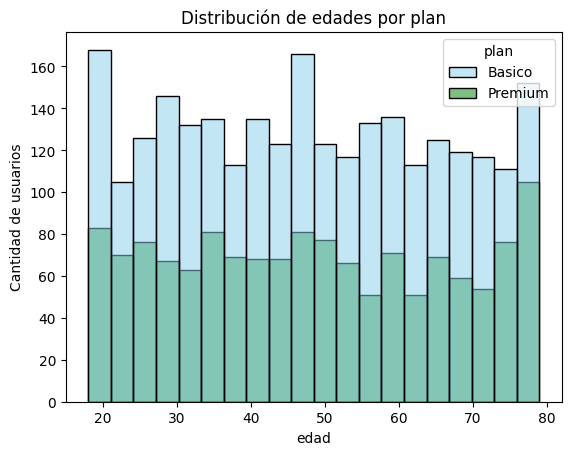

In [31]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age', hue='plan', hue_order=['Basico', 'Premium'],
    palette=['skyblue', 'green'], bins=20)
plt.title ("Distribución de edades por plan")
plt.xlabel ("edad")
plt.ylabel ("Cantidad de usuarios")
plt.show()


.


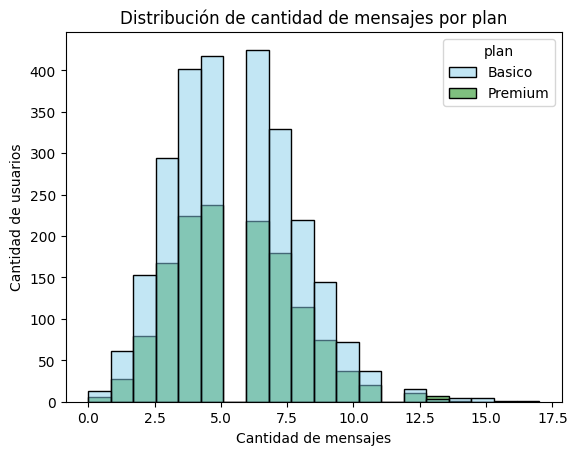

In [32]:

# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', hue_order=['Basico', 'Premium'],
    palette=['skyblue', 'green'], bins=20)
plt.title ("Distribución de cantidad de mensajes por plan")
plt.xlabel ("Cantidad de mensajes")
plt.ylabel ("Cantidad de usuarios")
plt.show()



💡Insights: 
- age: distribución simétrica (media 48.1 ≈ mediana 48, rango 18-79, sin cola). El pico en 48 viene de los 55 usuarios imputados con la mediana. Ambos planes tienen forma parecida, y Basico tiene barras más altas solo porque es el 65% de los usuarios.
- cant_mensajes: sesgada ligeramente a la derecha (media 5.5, mediana 5, máx. 17). No se ve un patrón distinto entre planes.
- cant_llamadas: sesgada a la derecha (media 4.5, mediana 4, máx. 15). Sin diferencia clara entre planes.
- cant_minutos_llamada: sesgada fuertemente a la derecha (media 23.3, mediana 19.8, máx. 155.7). Premium y Basico se comportan casi igual

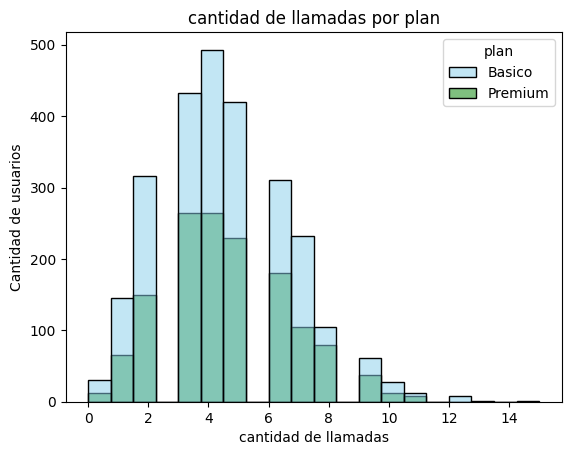

In [33]:

# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', hue_order=['Basico', 'Premium'],
    palette=['skyblue', 'green'], bins=20)
plt.title ("cantidad de llamadas por plan")
plt.xlabel ("cantidad de llamadas")
plt.ylabel ("Cantidad de usuarios")
plt.show()




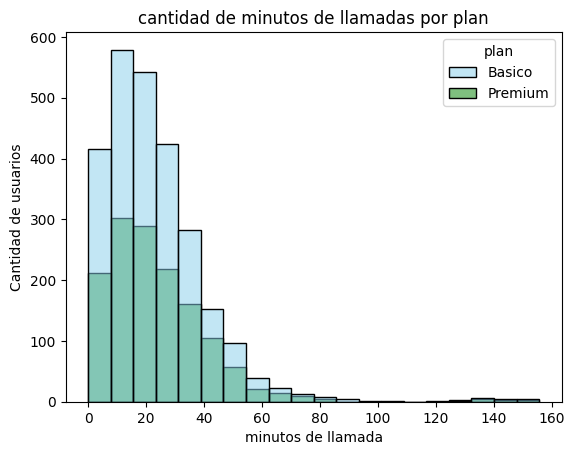

In [34]:

# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', hue_order=['Basico', 'Premium'],
    palette=['skyblue', 'green'], bins=20)
plt.title ("cantidad de minutos de llamadas por plan")
plt.xlabel ("minutos de llamada")
plt.ylabel ("Cantidad de usuarios")
plt.show()




### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

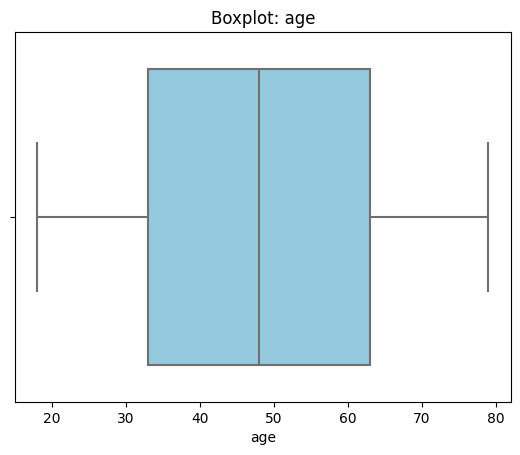

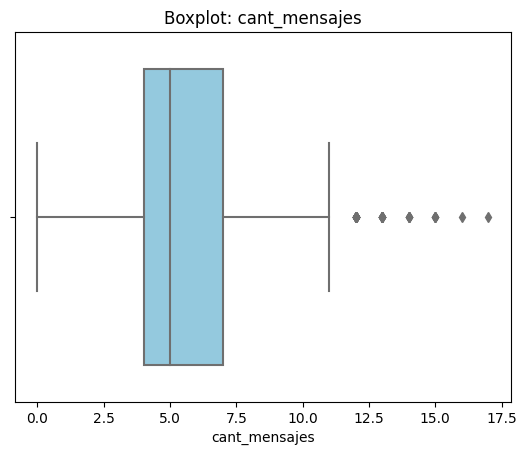

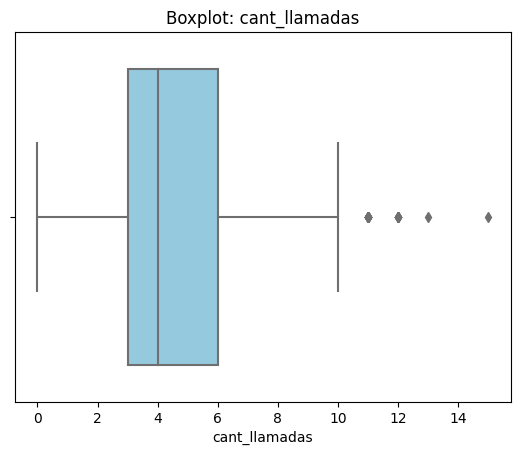

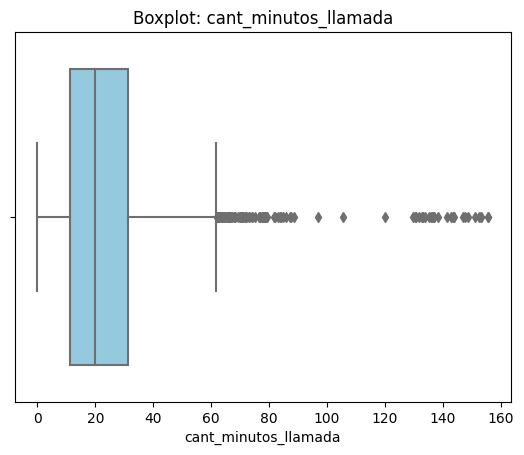

In [35]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile [col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show ()

💡Insights: 
- Age: no presenta outliers, la caja es amplia (aprox. de 33 a 63 años), los bigotes cubren de 18 a 79 y no hay puntos sueltos, 
- cant_mensajes: Sí presenta outliers, solo del lado derehco, la mediana ronda los 5 mensajes y los puntos sueltos parecen desde 12 hasta 17, aprox. son pocos usuarios con un envío de mensajes inusualmente alto.
- cant_llamadas: Sí presenta outliers, solo del lado derecho, la mediana es de aproximadamente 4 llamadas, y hay algunos puntos sueltos entre 11 y 15
- cant_minutos_llamada:Sí presenta outliers, y es la avriable con mas, la mediana es de aproximadamente 20 minutos, y hay muchos puntos arriba de 60, algunos llegando a más de 150 minutos. es una distribución sesgada a la derecha

In [36]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile [col].quantile(0.25)
    Q3 = user_profile [col].quantile(0.75)
    IQR = Q3-Q1
    limite_superior = Q3+ 1.5 * IQR 
    n_outliers = (user_profile[col]> limite_superior).sum()
    print (col)
    print ("Q1:", Q1, "Q3:", Q3, "IQR:", IQR)
    print ("Limite superior:", limite_superior)
    print ("Outliers:", n_outliers)
    print()





cant_mensajes
Q1: 4.0 Q3: 7.0 IQR: 3.0
Limite superior: 11.5
Outliers: 46

cant_llamadas
Q1: 3.0 Q3: 6.0 IQR: 3.0
Limite superior: 10.5
Outliers: 30

cant_minutos_llamada
Q1: 11.1075 Q3: 31.4125 IQR: 20.305
Limite superior: 61.870000000000005
Outliers: 109



In [37]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener outliers, son 46 usuarios con un maximo cercano a 17 mensajes, pocopor encima del limite de 11.5, son valores plausibles, no errores de registro, y representan usuarios que envian mas mensajes que el resto
- cant_llamadas: mantener outliers, son 30 usuarios con un maximo cercano a 15 llamadas, poco arriba del limite de 10.5, es un consumo alto pero realista, eliminarlos quitaría clientes legítimos del analisis
- cant_minutos_llamada: mantener pero marcarlos como "alto uso" para revision, son 109 usuarios, y el maximo ronda los 155 minutos, que son casi 2.5 veces el limite de 61.86, pueden ser clientes de uso muy intenso, pero tambien pueden ser errores de registro, conviene revisarlos en la segmentación antes de descartarlos

---

## 🧩Paso 6: Segmentación de Clientes


### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [38]:


# Crear columna grupo_uso
user_profile['grupo_uso'] = 'Alto uso'

user_profile.loc[(user_profile['cant_llamadas'] < 10) & 
                 (user_profile['cant_mensajes'] < 10), 'grupo_uso'] = 'Uso medio'

user_profile.loc[(user_profile['cant_llamadas'] < 5) & 
                 (user_profile['cant_mensajes'] < 5), 'grupo_uso'] = 'Bajo uso'

print(user_profile['grupo_uso'].value_counts())

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64


In [39]:

# verificar cambios
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [40]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = 'Adulto Mayor'
user_profile.loc[user_profile['age']<60, 'grupo_edad'] = 'Adulto' 
user_profile.loc[user_profile['age']<30, 'grupo_edad'] = 'Joven' 



In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [42]:
print("PLAN:")
print(user_profile['plan'].value_counts())

print("\nGRUPO DE USO:")
print(user_profile['grupo_uso'].value_counts())

print("\nGRUPO DE EDAD:")
print(user_profile['grupo_edad'].value_counts())

PLAN:
Basico     2595
Premium    1405
Name: plan, dtype: int64

GRUPO DE USO:
Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64

GRUPO DE EDAD:
Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


In [43]:
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100)
print(pd.crosstab(user_profile['plan'], user_profile['grupo_uso'], normalize='index') * 100)

grupo_uso     Alto uso   Bajo uso  Uso medio
grupo_edad                                  
Adulto        7.581764  18.087215  74.331021
Adulto Mayor  6.055646  21.031097  72.913257
Joven         6.710526  20.657895  72.631579
grupo_uso  Alto uso   Bajo uso  Uso medio
plan                                     
Basico     7.129094  19.768786  73.102119
Premium    6.619217  18.932384  74.448399


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

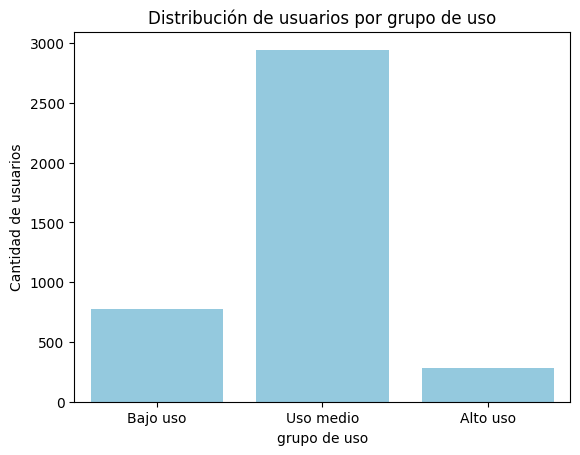

In [44]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title ("Distribución de usuarios por grupo de uso")
plt.xlabel ("grupo de uso")
plt.ylabel ("Cantidad de usuarios")
plt.show()

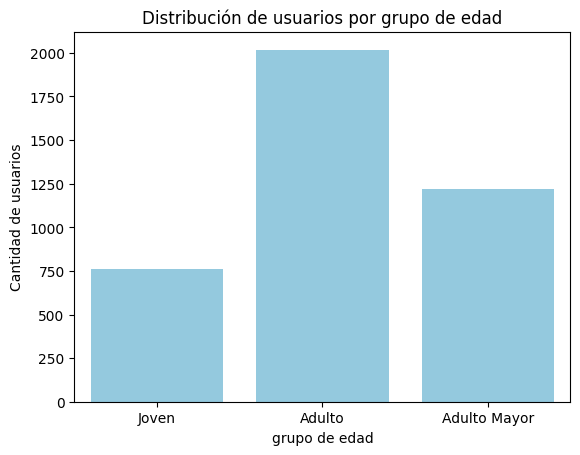

In [45]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='skyblue')
plt.title ("Distribución de usuarios por grupo de edad")
plt.xlabel ("grupo de edad")
plt.ylabel ("Cantidad de usuarios")
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-age: tenía el centinel -999, un valor imposible quw distorcionaba la media y la desviación estandar (123.2). Se reemplazó con la mediana.
-city: 565 registros sin ciudad (14.1% de 4,000): 469 nulos originales (11.7%) y 96 con el sentinel "?" (2.4%). Se dejaron como nulos, sin imputar.
-reg_date: 40 registros con año 2026, posterior al corte de 2024. Se marcaron como nulos.
-usage: 50 fechas nulas, además duration y lengthntienen nulos estructurales porque dependen del tipo de registro, se dejaron sin imputar.


🔍 **Segmentos por Edad**
-Adulto (30 a 59 años): el grupo más grande (50% de los usuarios).
-Adulto Mayor (60 o más) 30% de los usuarios 
-Joven (menos de 30) 19% de los usuarios
-Los tres grupos se comprtan de forma muy parecida, entre 73% y 74% está en uso medio, y alto uso va de 6.1% (adulto mayor) a 7.6%(adulto). Jovenes y adultos mayores tienen un poco mas de bajo uso, que los adultos 

📊 **Segmentos por Nivel de Uso**
-Uso medio: 74% de los usuarios, el nucleo del negocio
-bajo uso: 19%, con menos de 5 llamadas, y menos de 5 mensajes
-Alto uso 7%, incluye los outliers que se conservaron y marcaron, 46 mensajes, 30 llamadas y 109 en minutos de llamada. los minutos extremos merecen revisión por posible error de registro
-Por plan, Basico (64.9%) y Premium (35.1%) casi no difieren el nivel de su uso


➡️ Esto sugiere que ni la edad ni el plan parecen explicar significativamente
cuánto usa el servicio un cliente. El comportamiento de uso es un mejor criterio de segmentación que la demografía, y Premium no se distingue de Basico por consumo, así que su valor depende del precio y los beneficios, no del uso


💡 **Recomendaciones**
- Segmentar campañas por comportamiento (grupo_uso), no por edad o plan, porque los grupos demográficos se comportan casi igual.
-Revisar la propuesta de valor de Premium comparando precio y beneficios con plans.csv, ya que sus usuarios no consumen más que los de Basico.
-Ofrecer beneficios al segmento de Alto uso (más minutos o mensajes incluidos, o extras más baratos) para retenerlo, y revisar a los usuarios con minutos extremos para descartar fraude.
-Lanzar una oferta de precio bajo para Bajo uso (~19%) y reducir el riesgo de churn.
-Cruzar churn_date con grupo_uso en un siguiente análisis para saber qué segmento cancela más.
-Validar los datos en origen: que age no admita -999, que city no admita "?" y que las fechas no superen el corte.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`